In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from sklearn.datasets import make_blobs, make_moons, make_circles

D1 = make_blobs(n_samples=100, centers=2, cluster_std=1.0, random_state=7)
D2 = make_blobs(n_samples=200, centers=4, cluster_std=1.0, random_state=7)
D3 = make_moons(n_samples=200, noise=0.05, random_state=7)
D4 = make_circles(n_samples=200, noise=0.03, factor=0.5, random_state=7) 

Dataset 1: Nejmenší J = 194.63, ARI = 1.00
Dataset 2: Nejmenší J = 384.85, ARI = 1.00
Dataset 2 - J historie (první a poslední): 10776.76 -> 384.85
Dataset 3: Nejmenší J = 80.39, ARI = 0.24
Dataset 4: Nejmenší J = 78.74, ARI = -0.00


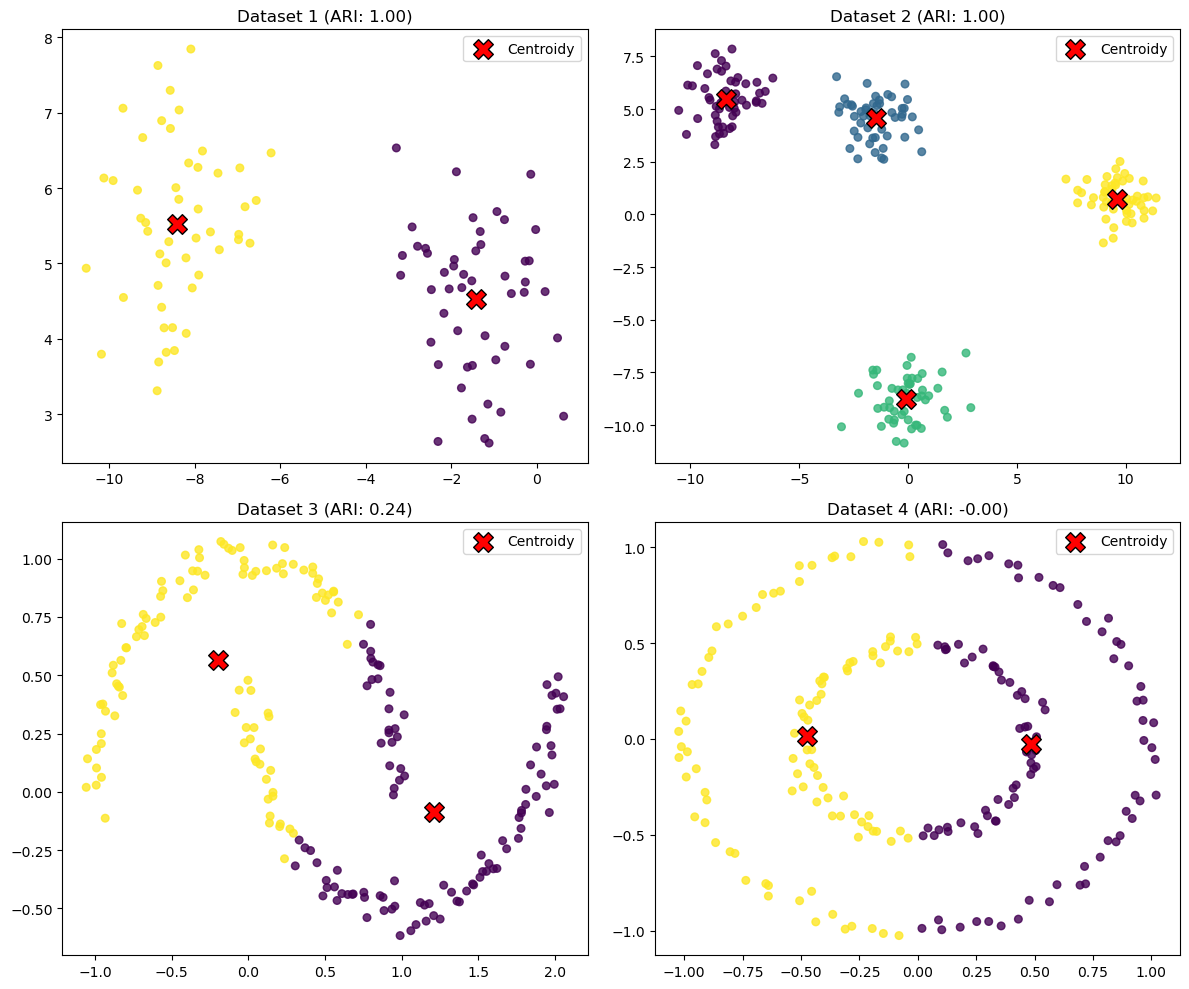

In [11]:
datasets = [
    ("Dataset 1", D1, 2),
    ("Dataset 2", D2, 4),
    ("Dataset 3", D3, 2),
    ("Dataset 4", D4, 2)
]

def kmeans_numpy(X, K, max_iter=100, tol=1e-6):
    n_samples = X.shape[0]
    random_indices = np.random.choice(n_samples, K, replace=False)
    centroids = X[random_indices]
    J_history = []
    
    for iteration in range(max_iter):
        d2 = (X**2).sum(axis=1, keepdims=True) - 2 * np.dot(X, centroids.T) + (centroids**2).sum(axis=1)
        labels = np.argmin(d2, axis=1)
        J = np.sum(np.min(d2, axis=1))
        J_history.append(J)
        
        if iteration > 0 and (J_history[-2] - J) < tol:
            break
            
        new_centroids = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centroids[j] for j in range(K)])
        centroids = new_centroids
        
    return labels, centroids, J_history

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for idx, (name, (X, y), K) in enumerate(datasets):
    best_J = float('inf')
    best_labels = None
    best_centroids = None
    best_history = None
    
    for _ in range(10):
        labels, centroids, history = kmeans_numpy(X, K)
        final_J = history[-1]
        if final_J < best_J:
            best_J = final_J
            best_labels = labels
            best_centroids = centroids
            best_history = history
            
    ari = adjusted_rand_score(y, best_labels)
    print(f"{name}: Nejmenší J = {best_J:.2f}, ARI = {ari:.2f}")
    
    if name == "Dataset 2":
        print(f"Dataset 2 - J historie (první a poslední): {best_history[0]:.2f} -> {best_history[-1]:.2f}")
    
    ax = axes[idx]
    ax.scatter(X[:, 0], X[:, 1], c=best_labels, cmap='viridis', s=30, alpha=0.8)
    ax.scatter(best_centroids[:, 0], best_centroids[:, 1], c='red', marker='X', s=200, edgecolor='black', label='Centroidy')
    ax.set_title(f"{name} (ARI: {ari:.2f})")
    ax.legend()

plt.tight_layout()
plt.show()